# 03 — Polynomial Regression
## Practical ML assignment: predict house price (`price_etb`)

**Goal:** Compare degree 1 (ordinary linear regression), degree 2, and degree 3 polynomial regression using `size_sqm` as the single predictor. This follows the workbook's Practice Questions.

### Important methodology
- Target: `price_etb` (ETB).
- Predictor: `size_sqm` (square metres).
- Split: 80% training / 20% test, `random_state=42`.
- All three degrees use the same rows in train and test, making comparison fair.
- Polynomial features are generated inside a pipeline fitted on training data.
- The test set is used for final comparison only; do not keep changing the model based on repeated test-set inspection.
- Degree 1 is the straight-line baseline. Degree 2 and 3 allow curvature.


## 1. Import libraries and load the dataset

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "price_etb"
DATA_FILENAME = "Practical_Dataset for ML.xlsx"

# Supports running from either ML_Course/ or ML_Course/notebooks/.
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd
candidates = [
    Path("data") / DATA_FILENAME,
    Path("ML_Course") / "data" / DATA_FILENAME,
    Path("..") / "data" / DATA_FILENAME,
    Path("..") / ".." / "data" / DATA_FILENAME, 
    Path("ML_Course") / DATA_FILENAME,
    Path("..") / ".." / ".." / "data" / DATA_FILENAME, 
    Path("/mnt/data") / DATA_FILENAME,
]

DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. Put it in ML_Course/data/ "
        "or directly inside ML_Course, then rerun this cell."
    )

df = pd.read_excel(DATA_PATH, sheet_name="Data")
print("Loaded:", DATA_PATH)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Loaded: ..\..\data\Practical_Dataset for ML.xlsx
Dataset shape: (3000, 17)
Columns: ['house_id', 'size_sqm', 'num_bedrooms', 'num_bathrooms', 'floor_level', 'age_years', 'renovated', 'distance_to_bole_km', 'distance_to_main_road_m', 'has_garage', 'parking_spaces', 'has_garden', 'security_service', 'water_supply_hours_per_day', 'school_rating', 'days_on_market', 'price_etb']


,house_id,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market,price_etb
0,AA-10000,84.8,3,3,0,12,1,9.54,195,1,1,0,1,18.1,4.2,56,4664000
1,AA-10001,142.1,4,3,12,21,0,2.03,119,1,3,0,1,9.1,6.1,19,6209000
2,AA-10002,110.3,3,3,0,6,0,6.96,260,0,0,1,0,24.0,6.7,19,5804000
3,AA-10003,32.0,1,1,11,5,0,7.28,157,0,0,0,0,13.5,4.6,74,1134000
4,AA-10004,61.9,2,1,6,13,0,10.04,153,1,2,0,1,18.1,7.5,12,1810000


In [3]:
def regression_metrics(y_true, y_pred):
    """Return common regression metrics in the target's original units."""
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

def evaluate_train_test(model, X_train, y_train, X_test, y_test):
    """Evaluate an already-fitted model on both train and test data."""
    rows = []
    for split_name, X_part, y_part in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test),
    ]:
        pred = model.predict(X_part)
        row = {"Dataset": split_name}
        row.update(regression_metrics(y_part, pred))
        rows.append(row)
    return pd.DataFrame(rows).set_index("Dataset")

def interpret_metrics(metrics):
    """Print a short interpretation from the model's actual metric values."""
    train = metrics.loc["Train"]
    test = metrics.loc["Test"]
    print(f"Test MAE: {test['MAE']:,.2f} ETB.")
    print(f"Test RMSE: {test['RMSE']:,.2f} ETB.")
    print(f"Test R²: {test['R2']:.4f}.")
    gap = test["RMSE"] - train["RMSE"]
    print(f"Test RMSE minus train RMSE: {gap:,.2f} ETB.")
    if gap > max(0.10 * train["RMSE"], 1):
        print("Interpretation: test error is noticeably higher than train error; check for overfitting.")
    elif gap < -max(0.10 * train["RMSE"], 1):
        print("Interpretation: test error is lower than train error. This can happen with a harder training set or sampling variation; it is not automatically a problem.")
    else:
        print("Interpretation: train and test RMSE are relatively close; check the absolute error size as well.")
    if test["R2"] < 0:
        print("Test R² is negative: on this test set, the model is worse than predicting the test-set mean.")
    else:
        print("Test R² is non-negative: the model improves on the test-set mean baseline under the R² definition.")
    print("Always judge errors against the practical context and compare models on the same test rows.")


## 2. Inspect relevant columns and missing values

The provided workbook's `Data` sheet has 3,000 rows. The data dictionary identifies `size_sqm` as a useful single predictor and `price_etb` as the target. Confirm these columns in the output before continuing.

In [4]:
required = {"size_sqm", TARGET}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns missing from workbook: {missing_columns}")

print("Missing values in size_sqm:", df["size_sqm"].isna().sum())
print("Missing values in target:", df[TARGET].isna().sum())
print(df[["size_sqm", TARGET]].describe().T)


Missing values in size_sqm: 0
Missing values in target: 0
            count          mean           std       min        25%        50%  \
size_sqm   3000.0  1.406660e+02  9.025080e+01      32.0       79.8      111.1   
price_etb  3000.0  6.000234e+06  4.914972e+06  556000.0  2872500.0  4378000.0   

                   75%         max  
size_sqm       176.625       572.4  
price_etb  7321500.000  40973000.0  


## 3. Create the train/test split once

This split is specific to the selected predictor and target, but uses the same 80/20 ratio and random seed recommended for notebooks 01 and 02. If your previous notebooks used a different `test_size`, `random_state`, row filtering, or split method, match those choices here to ensure identical test observations.

In [5]:
# Keep rows with an observed target. The supplied size_sqm column has no missing values.
model_df = df[["size_sqm", TARGET]].dropna(subset=[TARGET]).copy()
X = model_df[["size_sqm"]]
y = model_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Total observations: {len(model_df)}")
print(f"Training observations: {len(X_train)} ({len(X_train)/len(model_df):.1%})")
print(f"Test observations: {len(X_test)} ({len(X_test)/len(model_df):.1%})")


Total observations: 3000
Training observations: 2400 (80.0%)
Test observations: 600 (20.0%)


## 4. Fit degree 1, 2, and 3 models

`PolynomialFeatures` expands `size_sqm` into powers of the feature. For degree 2 it creates `size_sqm` and `size_sqm²`; for degree 3 it also adds `size_sqm³`. The linear regression algorithm then estimates the coefficients.

The imputer is included in each pipeline to keep preprocessing inside the training workflow, although `size_sqm` is complete in this workbook.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

degrees = [1, 2, 3]
poly_models = {}

for degree in degrees:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("polynomial", PolynomialFeatures(degree=degree, include_bias=False)),
        ("regressor", LinearRegression())
    ])
    model.fit(X_train, y_train)
    poly_models[degree] = model

print("Fitted models for degrees:", list(poly_models.keys()))


Fitted models for degrees: [1, 2, 3]


## 5. Evaluate on both training and test data

In [7]:
metric_tables = []
for degree, model in poly_models.items():
    metrics = evaluate_train_test(model, X_train, y_train, X_test, y_test)
    metrics["Degree"] = degree
    metrics["Model"] = f"Polynomial degree {degree}"
    metric_tables.append(metrics.reset_index())

metrics_by_degree = pd.concat(metric_tables, ignore_index=True)
display(
    metrics_by_degree[["Model", "Degree", "Dataset", "MAE", "MSE", "RMSE", "R2"]]
    .sort_values(["Degree", "Dataset"])
    .round(3)
)

test_comparison = (
    metrics_by_degree[metrics_by_degree["Dataset"] == "Test"]
    [["Degree", "MAE", "MSE", "RMSE", "R2"]]
    .sort_values("RMSE")
    .reset_index(drop=True)
)
print("Test-set comparison (lower MAE/RMSE and usually higher R² are preferable):")
display(test_comparison.round(4))
best_degree_by_test_rmse = int(test_comparison.iloc[0]["Degree"])
print(f"Lowest test RMSE among these three models: degree {best_degree_by_test_rmse}.")


,Model,Degree,Dataset,MAE,MSE,RMSE,R2
1,Polynomial degree 1,1,Test,1603658.872,6.987126e+12,2643317.179,0.739
0,Polynomial degree 1,1,Train,1485776.063,5.263627e+12,2294259.610,0.776
3,Polynomial degree 2,2,Test,1596685.374,7.002569e+12,2646236.714,0.738
2,Polynomial degree 2,2,Train,1473812.985,5.254887e+12,2292353.935,0.776
5,Polynomial degree 3,3,Test,1601493.240,6.877131e+12,2622428.447,0.743
4,Polynomial degree 3,3,Train,1477656.949,5.288233e+12,2299615.817,0.775


Test-set comparison (lower MAE/RMSE and usually higher R² are preferable):


,Degree,MAE,MSE,RMSE,R2
0,3,1.601493e+06,6.877131e+12,2.622428e+06,0.7429
1,1,1.603659e+06,6.987126e+12,2.643317e+06,0.7388
2,2,1.596685e+06,7.002569e+12,2.646237e+06,0.7382


Lowest test RMSE among these three models: degree 3.


### How to interpret these metrics
- **MAE:** average absolute error in ETB; lower is better.
- **RMSE:** error in ETB that penalizes large mistakes more heavily; lower is better.
- **MSE:** squared error in ETB²; lower is better, but less directly interpretable than RMSE.
- **R²:** performance relative to predicting the test-set mean; it can be negative.

Choose the degree using training-only cross-validation in a rigorous model-selection workflow. The code above shows the test comparison requested in the practice sheet, but avoid repeatedly changing degrees or features based on test results. A degree with lower training error is not necessarily better on unseen houses.

## 6. Plot the scatter and all three fitted curves

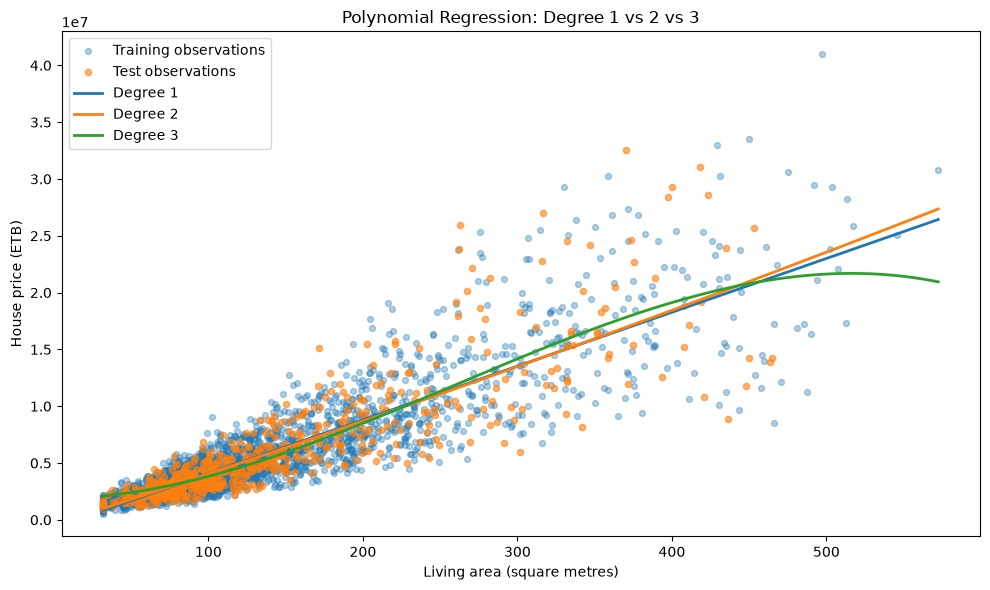

In [8]:
# Sort x-values so fitted curves draw smoothly.
x_grid = np.linspace(X["size_sqm"].min(), X["size_sqm"].max(), 400)
X_grid = pd.DataFrame({"size_sqm": x_grid})

plt.figure(figsize=(10, 6))
plt.scatter(X_train["size_sqm"], y_train, alpha=0.35, s=18, label="Training observations")
plt.scatter(X_test["size_sqm"], y_test, alpha=0.60, s=20, label="Test observations")

for degree, model in poly_models.items():
    y_grid = model.predict(X_grid)
    plt.plot(x_grid, y_grid, linewidth=2, label=f"Degree {degree}")

plt.xlabel("Living area (square metres)")
plt.ylabel("House price (ETB)")
plt.title("Polynomial Regression: Degree 1 vs 2 vs 3")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Residual diagnostics for the selected degree

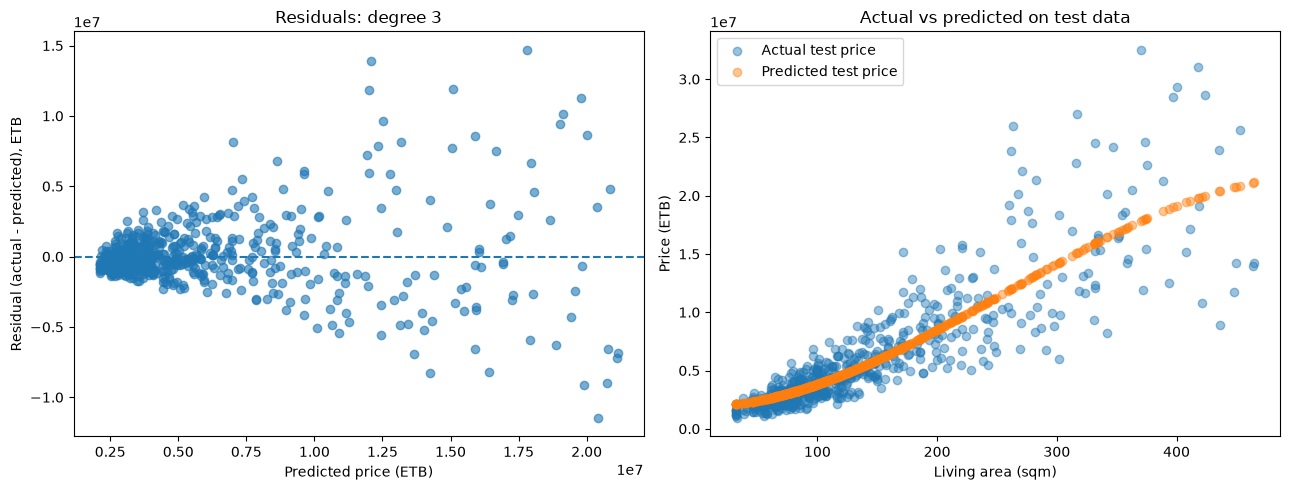

,MAE,MSE,RMSE,R2
Dataset,,,,
Train,1477656.949,5.288233e+12,2299615.817,0.775
Test,1601493.240,6.877131e+12,2622428.447,0.743


Test MAE: 1,601,493.24 ETB.
Test RMSE: 2,622,428.45 ETB.
Test R²: 0.7429.
Test RMSE minus train RMSE: 322,812.63 ETB.
Interpretation: test error is noticeably higher than train error; check for overfitting.
Test R² is non-negative: the model improves on the test-set mean baseline under the R² definition.
Always judge errors against the practical context and compare models on the same test rows.


In [9]:
selected_model = poly_models[best_degree_by_test_rmse]
selected_predictions = selected_model.predict(X_test)
residuals = y_test.to_numpy() - selected_predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(selected_predictions, residuals, alpha=0.6)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted price (ETB)")
axes[0].set_ylabel("Residual (actual - predicted), ETB")
axes[0].set_title(f"Residuals: degree {best_degree_by_test_rmse}")

axes[1].scatter(X_test["size_sqm"], y_test, alpha=0.45, label="Actual test price")
axes[1].scatter(X_test["size_sqm"], selected_predictions, alpha=0.45, label="Predicted test price")
axes[1].set_xlabel("Living area (sqm)")
axes[1].set_ylabel("Price (ETB)")
axes[1].set_title("Actual vs predicted on test data")
axes[1].legend()
plt.tight_layout()
plt.show()

selected_metrics = evaluate_train_test(
    selected_model, X_train, y_train, X_test, y_test
)
display(selected_metrics.round(3))
interpret_metrics(selected_metrics)


## 8. Coefficients and interpretation

For a polynomial model, coefficients on squared and cubed terms describe curvature; they are not interpreted as a simple constant price increase per extra square metre. Degree 1 has a constant slope, while degree 2/3 have slopes that vary with `size_sqm`.

The intercept is the fitted price at `size_sqm = 0`, which is outside the meaningful range of this dataset, so do not give it a practical house-price interpretation.

## 9. Conclusion template

After running the notebook, write your own conclusion using the actual metric table:
1. Which degree had the lowest test MAE/RMSE?
2. Did training error fall as degree increased?
3. Did test error also improve, or did it worsen?
4. Does the curve follow the overall trend without unrealistic wiggles?
5. Why is the selected model a reasonable balance of fit and generalization?

**Do not claim a model is best until you have checked the displayed metrics.**

## 10. Save metrics

The following saves the results under `outputs/metrics/` in your project folder.

In [10]:
metrics_dir = PROJECT_ROOT / "outputs" / "metrics"
plots_dir = PROJECT_ROOT / "outputs" / "plots"
metrics_dir.mkdir(parents=True, exist_ok=True)
plots_dir.mkdir(parents=True, exist_ok=True)

metrics_by_degree.to_csv(metrics_dir / "03_polynomial_train_test_metrics.csv", index=False)
test_comparison.to_csv(metrics_dir / "03_polynomial_test_comparison.csv", index=False)
print("Saved polynomial regression metrics to:", metrics_dir)


Saved polynomial regression metrics to: C:\Users\hp\ML_Course\Notebooks\Regression\outputs\metrics
